In [51]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import datasets as load_datasets

#Loading data
datasets = load_datasets.load_dataset('lukebarousse/data_jobs')
df = datasets['train'].to_pandas()

#Data cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else(x))

In [52]:
df_DA = df[df['job_title_short'] == 'Data Analyst']

df_DA['job_posted_month_no'] = df['job_posted_date'].dt.month

df_DA_explode = df_DA.explode('job_skills')

df_DA_pivot = df_DA_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)

df_DA_pivot.loc['Total'] = df_DA_pivot.sum()
df_DA_pivot = df_DA_pivot[df_DA_pivot.loc['Total'].sort_values(ascending=False).index]

df_DA_pivot = df_DA_pivot.drop('Total')

In [53]:
df_DA_pivot = df_DA_pivot.reset_index()
df_DA_pivot['job_posted_month'] = df_DA_pivot['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))
df_DA_pivot = df_DA_pivot.set_index('job_posted_month')
df_DA_pivot = df_DA_pivot.drop(columns='job_posted_month_no')

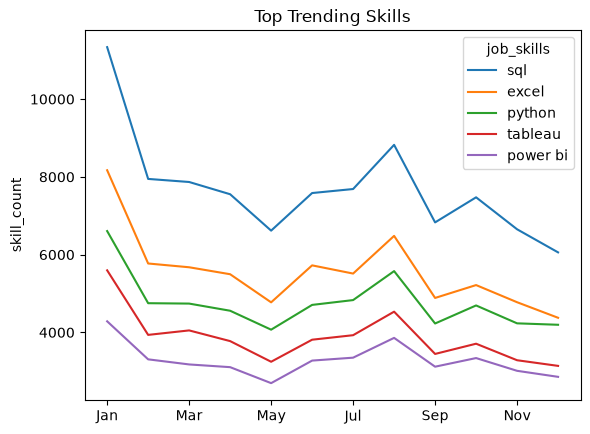

In [54]:
df_DA_pivot.iloc[:, :5].plot(kind='line')
plt.title('Top Trending Skills')
plt.ylabel('skill_count')
plt.xlabel('')
plt.show()